# B3 — APTOS2019

B1 plus targeted grade 3 sampling to 10% with proportional non-grade-3 replacement tests whether more exposure improves grade 3 recognition.

[Notebook index](../README.md) · [Experiment audit](../../docs/NOTEBOOK_EXPERIMENT_AUDIT.md)

## Protocol and reproducibility

The historical runner and grade 3 sampler were external. The export records their hashes. [foundation adaptation](../../novelty/foundation_adaptation.py) is a component reference and exposes B0–B2 only.

Frozen seed 42 manifest, SHA group isolation, grade order 0–4. Validation uses deterministic transforms and original support. The notebook creates no split.

## Model, inputs and environment

Official Hugging Face ConvNeXt-Tiny V1, pooled width 768. A linear categorical head emits five logits. Parameter counts are not published in this run evidence.

EXIF transpose and RGB, then the pinned official processor at 224 px for resize/crop, rescale and normalization. B1 train-only augmentation is keyed by seed, epoch and image ID. It applies horizontal flip (p=0.50), field-of-view guarded rotation (p=0.50, ±7°), brightness (p=0.30, factor 0.90–1.10), and contrast (p=0.30, factor 0.90–1.10), in that order.

The evidence view requires Python, Jupyter and IPython. Optional source workflows rely on the run-specific PyTorch, Transformers, Pillow and NumPy environment, a verified local snapshot, and external datasets/manifests. The CLI and protocol links describe hardware, caching and environment details.

### Read committed evidence

The setup uses the dataset-specific result and performs no training or inference.

In [ ]:
from pathlib import Path
import hashlib
import json
import os
import sys

from IPython.display import JSON, display

configured_root = os.environ.get("DR_RESEARCH_ROOT")
start = Path(configured_root).expanduser().resolve() if configured_root else Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents)
             if (p / "notebooks/experiment_workflow.py").is_file() and (p / "novelty_integrated").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Set DR_RESEARCH_ROOT to the reviewed repository checkout.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

METHOD, DATASET = 'B3', 'APTOS2019'
EVIDENCE = 'novelty/convnext_b0_b4/validation_evidence.json'
blob = json.loads((ROOT / EVIDENCE).read_text(encoding='utf-8'))
RUNS = [r for r in blob['runs'] if r['dataset'] == DATASET and (r['arm'].startswith('B4-') if METHOD == 'B4' else r['arm'] == METHOD)]
CONFIG = RUNS[0]['configuration'] if RUNS else {}
CHECKPOINT_SHA256 = 'b6c69fd019acadb75a2a705259749044b08f117c53cc6ec876bbc420287ec142'
print(f'{METHOD} {DATASET}: {len(RUNS)} published run(s) in this notebook.')

### Optional manifest and checkpoint byte checks

Set `DR_ARTIFACT_ROOT` and optionally `DR_CHECKPOINT` before enabling this read-only gate.

In [ ]:
VERIFY_LOCAL_PROVENANCE = False
if VERIFY_LOCAL_PROVENANCE:
    artifact = os.environ.get("DR_ARTIFACT_ROOT")
    checkpoint = os.environ.get("DR_CHECKPOINT")
    expected = CONFIG.get("manifest", {}).get("manifest_sha256")
    if not artifact or not expected:
        raise ValueError("Set DR_ARTIFACT_ROOT and use a notebook with a verified frozen manifest.")
    manifest = Path(artifact) / "cad_vit_runs" / "manifests" / f"{DATASET}_seed42.csv"
    with manifest.open("rb") as stream:
        if hashlib.file_digest(stream, "sha256").hexdigest() != expected:
            raise ValueError("Frozen manifest hash differs.")
    print("Frozen manifest SHA-256 matches.")
    if checkpoint:
        run_id = os.environ.get("DR_RECORDED_RUN_ID")
        receipts = {r.get("id", r.get("experiment")):
                    r.get("source_sha256", {}).get("best.pt") or
                    r.get("checkpoint_sidecars", {}).get("best.pt", {}).get("sha256") for r in RUNS}
        expected_checkpoint = receipts.get(run_id) if run_id else CHECKPOINT_SHA256
        if len(RUNS) > 1 and not run_id:
            raise ValueError("Set DR_RECORDED_RUN_ID to the relevant B4-Q or B4-R evidence ID.")
        if not expected_checkpoint:
            raise ValueError("No repository-verified checkpoint SHA-256 exists for this run.")
        with Path(checkpoint).open("rb") as stream:
            if hashlib.file_digest(stream, "sha256").hexdigest() != expected_checkpoint:
                raise ValueError("Checkpoint hash differs.")
        print("Checkpoint SHA-256 matches without deserializing weights.")

## B3 recorded configuration and history

[Authoritative aggregate JSON](../../novelty/convnext_b0_b4/validation_evidence.json).

| Recorded field | Value |
| --- | --- |
| model_kind | convnext_tiny |
| mode | full |
| seed | 42 |
| epochs | 20 |
| micro_batch | 32 |
| accumulation | 1 |
| effective_batch | 32 |
| precision | bf16 |
| optimizer | AdamW |
| backbone_lr | 1e-05 |
| head_lr | 0.001 |
| weight_decay | 0.01 |
| selection | max validation macro-F1; tie lower validation loss; tie earliest epoch |
| training_loss | ordinary CE |
| implementation_sha256 | 6adb1c65bd030c8924bc89e8f471833f0e574a518ba0dd2408170ee6b427be47 |
| manifest_sha256 | 73d1546e3c2fd2bf9e3d0fd10af914cb523d28e4bc8e1f25212af454d4be8854 |
| train / validation counts | {'train': 2930, 'val': 366} |
| model revision | 6166b7613034066690a621d8bf25ffdf181a34f0 |
| model weights SHA-256 | 1fe15b2eba9e355de14c4e244e6365bf61ffef84da7d3442c0afbb2d8564f477 |
| processor config SHA-256 | fd575b890da5a949493e1d1e7a70bfcb9e4b99fe444004d2dbfa253add254741 |

```json
{
  "augmentation": {
    "implementation_sha256": "cd7cedcbadda52aff69ef9096f24803703d1ec7b1b90dde19d5bdbc41c8c8ea3",
    "pillow_version": "11.1.0",
    "protocol": {
      "brightness_factor": [
        0.9,
        1.1
      ],
      "brightness_probability": 0.3,
      "contrast_factor": [
        0.9,
        1.1
      ],
      "contrast_probability": 0.3,
      "fov_proxy_threshold_max_channel": 8,
      "horizontal_flip_probability": 0.5,
      "minimum_fov_proxy_retention": 0.99,
      "name": "B1-retinal-conservative-v1",
      "order": [
        "horizontal_flip",
        "rotation",
        "brightness",
        "contrast"
      ],
      "rotation_attempts": 8,
      "rotation_degrees": [
        -7.0,
        7.0
      ],
      "rotation_fill": [
        0,
        0,
        0
      ],
      "rotation_probability": 0.5,
      "rotation_resample": "BICUBIC"
    }
  },
  "sampling": {
    "augmentation": "B1 unchanged; seed/epoch/image_id",
    "protocol": "B3-grade3-targeted-sampling-v1",
    "replacement": "proportional non-grade3 removal",
    "sampler_sha256": "ff6e2a7f999446a6bcbbb78d25305a96dbd6499754530170d521575f93f2f767",
    "seed_rule": "seed + epoch",
    "target_fraction": 0.1,
    "target_grade": 3
  }
}
```

The next tables show all completed epochs. An em dash means the metric was not recorded. The source JSON retains full precision, resource fields and nested histories.

### Training metrics

| Epoch | Total loss | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | 0.868011 | 0.675768 | 0.38613 | 0.612315 | 0.582449 | 0.564164 |
| 2 | 0.584903 | 0.785324 | 0.592456 | 0.760416 | 0.835444 | 0.301365 |
| 3 | 0.502324 | 0.814334 | 0.656339 | 0.79843 | 0.873977 | 0.250512 |
| 4 | 0.457267 | 0.824915 | 0.688331 | 0.814276 | 0.887587 | 0.232765 |
| 5 | 0.417629 | 0.832423 | 0.703002 | 0.823259 | 0.890166 | 0.227304 |
| 6 | 0.379605 | 0.855973 | 0.742579 | 0.847933 | 0.90482 | 0.195904 |
| 7 | 0.3462 | 0.872014 | 0.779482 | 0.867184 | 0.917976 | 0.172355 |
| 8 | 0.311314 | 0.888055 | 0.80953 | 0.884724 | 0.931244 | 0.149829 |
| 9 | 0.278772 | 0.897952 | 0.823194 | 0.894085 | 0.933361 | 0.139932 |
| 10 | 0.234789 | 0.918771 | 0.861767 | 0.916709 | 0.945329 | 0.113993 |
| 11 | 0.207792 | 0.928669 | 0.880261 | 0.927019 | 0.953897 | 0.0982935 |
| 12 | 0.187472 | 0.936177 | 0.893171 | 0.935197 | 0.958305 | 0.0887372 |
| 13 | 0.160359 | 0.947782 | 0.914354 | 0.947108 | 0.966253 | 0.0723549 |
| 14 | 0.13412 | 0.959386 | 0.93319 | 0.958853 | 0.9734 | 0.056314 |
| 15 | 0.1186 | 0.962116 | 0.938598 | 0.961782 | 0.975535 | 0.0525597 |
| 16 | 0.097702 | 0.970307 | 0.951957 | 0.970153 | 0.982381 | 0.0399317 |
| 17 | 0.0864555 | 0.97099 | 0.951886 | 0.970748 | 0.980238 | 0.0406143 |
| 18 | 0.0755066 | 0.977474 | 0.962655 | 0.97731 | 0.984603 | 0.0320819 |
| 19 | 0.0635348 | 0.980546 | 0.967128 | 0.980456 | 0.987224 | 0.0269625 |
| 20 | 0.0583855 | 0.98157 | 0.968826 | 0.981492 | 0.988846 | 0.0249147 |

### Validation metrics

| Epoch | CE | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | 0.635525 | 0.754098 | 0.494629 | 0.726551 | 0.827952 | 0.325137 |
| 2 | 0.57746 | 0.76776 | 0.497215 | 0.735486 | 0.835827 | 0.306011 |
| 3 | 0.524609 | 0.778689 | 0.537656 | 0.755696 | 0.851122 | 0.289617 |
| 4 | 0.507719 | 0.806011 | 0.638408 | 0.799821 | 0.875614 | 0.251366 |
| 5 | 0.497916 | 0.797814 | 0.609085 | 0.79029 | 0.879859 | 0.251366 |
| 6 | 0.491696 | 0.814208 | 0.64177 | 0.805773 | 0.888036 | 0.234973 |
| 7 | 0.497929 | 0.811475 | 0.650963 | 0.808945 | 0.893358 | 0.23224 |
| 8 | 0.49004 | 0.806011 | 0.622046 | 0.798917 | 0.89162 | 0.240437 |
| 9 | 0.494316 | 0.825137 | 0.69223 | 0.827646 | 0.902229 | 0.218579 |
| 10 | 0.503422 | 0.830601 | 0.699488 | 0.832857 | 0.90944 | 0.20765 |
| 11 | 0.520743 | 0.825137 | 0.693416 | 0.829378 | 0.90541 | 0.218579 |
| 12 | 0.520127 | 0.808743 | 0.65762 | 0.809202 | 0.891076 | 0.240437 |
| 13 | 0.557365 | 0.814208 | 0.635086 | 0.810097 | 0.896674 | 0.23224 |
| 14 | 0.537999 | 0.827869 | 0.691507 | 0.827477 | 0.903557 | 0.215847 |
| 15 | 0.57119 | 0.822404 | 0.677323 | 0.823127 | 0.894499 | 0.23224 |
| 16 | 0.631233 | 0.814208 | 0.67779 | 0.818228 | 0.895335 | 0.237705 |
| 17 | 0.614641 | 0.819672 | 0.686569 | 0.822673 | 0.897291 | 0.23224 |
| 18 | 0.618829 | 0.81694 | 0.657202 | 0.815894 | 0.892486 | 0.240437 |
| 19 | 0.652021 | 0.811475 | 0.672339 | 0.812245 | 0.893821 | 0.240437 |
| 20 | 0.718008 | 0.827869 | 0.700624 | 0.829804 | 0.899896 | 0.221311 |

### Timing, memory and validation errors

| Epoch | Train s | Validation s | Train input s | Val input s | Train images/s | Val images/s | Peak VRAM B | Process RSS B | Under | Over | High-confidence wrong |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 342.457 | 21.9823 | 328.932 | 21.4875 | 8.55581 | 16.6498 | 2665480192 | 3378749440 | 50 | 40 | 0 |
| 2 | 333.354 | 21.3767 | 321.11 | 20.7971 | 8.78944 | 17.1215 | 2665480192 | 3378749440 | 50 | 35 | 1 |
| 3 | 338.365 | 19.6395 | 325.63 | 19.1495 | 8.65929 | 18.6359 | 2665480192 | 3378749440 | 44 | 37 | 1 |
| 4 | 331.806 | 19.9108 | 318.764 | 19.4196 | 8.83046 | 18.382 | 2665480192 | 3378749440 | 32 | 39 | 2 |
| 5 | 336.109 | 18.7137 | 323.26 | 18.2204 | 8.71741 | 19.5579 | 2665480192 | 3378749440 | 44 | 30 | 5 |
| 6 | 317.073 | 19.0172 | 304.455 | 18.5201 | 9.24078 | 19.2457 | 2665480192 | 3401166848 | 35 | 33 | 9 |
| 7 | 332.906 | 19.7466 | 320.336 | 19.2564 | 8.80128 | 18.5348 | 2665480192 | 3401166848 | 37 | 32 | 12 |
| 8 | 332.356 | 19.6298 | 319.677 | 19.1163 | 8.81584 | 18.6451 | 2665480192 | 3401166848 | 34 | 37 | 12 |
| 9 | 338.125 | 19.6726 | 324.825 | 19.1671 | 8.66544 | 18.6045 | 2665480192 | 3482865664 | 30 | 34 | 11 |
| 10 | 344.228 | 19.7351 | 331.617 | 19.1843 | 8.5118 | 18.5457 | 2665480192 | 3621314560 | 31 | 31 | 14 |
| 11 | 338.453 | 19.4165 | 325.76 | 18.9049 | 8.65704 | 18.85 | 2665480192 | 3621314560 | 30 | 34 | 16 |
| 12 | 337.559 | 20.1659 | 324.737 | 19.6786 | 8.67995 | 18.1494 | 2665480192 | 3621314560 | 35 | 35 | 15 |
| 13 | 339.763 | 20.2628 | 326.661 | 19.734 | 8.62365 | 18.0627 | 2665480192 | 3621314560 | 36 | 32 | 19 |
| 14 | 338.915 | 21.6104 | 325.892 | 21.1158 | 8.64522 | 16.9363 | 2665480192 | 3621314560 | 34 | 29 | 16 |
| 15 | 336.573 | 21.5498 | 323.559 | 21.0608 | 8.7054 | 16.9839 | 2665480192 | 3621314560 | 33 | 32 | 20 |
| 16 | 330.474 | 18.8822 | 317.777 | 18.3656 | 8.86604 | 19.3833 | 2665480192 | 3621314560 | 31 | 37 | 25 |
| 17 | 326.7 | 19.0754 | 313.637 | 18.587 | 8.96847 | 19.187 | 2665480192 | 3693522944 | 30 | 36 | 26 |
| 18 | 335.593 | 19.7555 | 322.773 | 19.2639 | 8.73081 | 18.5265 | 2665480192 | 3693522944 | 33 | 34 | 25 |
| 19 | 336.982 | 19.3572 | 324.025 | 18.869 | 8.69481 | 18.9076 | 2665480192 | 3693522944 | 33 | 36 | 24 |
| 20 | 333.423 | 19.6925 | 320.672 | 19.204 | 8.78763 | 18.5858 | 2665480192 | 3693522944 | 32 | 31 | 34 |

### Learning rates and checkpoint tracking

| Epoch | Backbone LR | Head LR | Class weights active | Best epoch so far | Best updated |
| --- | --- | --- | --- | --- | --- |
| 1 | 1e-05 | 0.001 | — | 1 | True |
| 2 | 1e-05 | 0.001 | — | 2 | True |
| 3 | 1e-05 | 0.001 | — | 3 | True |
| 4 | 1e-05 | 0.001 | — | 4 | True |
| 5 | 1e-05 | 0.001 | — | 4 | False |
| 6 | 1e-05 | 0.001 | — | 6 | True |
| 7 | 1e-05 | 0.001 | — | 7 | True |
| 8 | 1e-05 | 0.001 | — | 7 | False |
| 9 | 1e-05 | 0.001 | — | 9 | True |
| 10 | 1e-05 | 0.001 | — | 10 | True |
| 11 | 1e-05 | 0.001 | — | 10 | False |
| 12 | 1e-05 | 0.001 | — | 10 | False |
| 13 | 1e-05 | 0.001 | — | 10 | False |
| 14 | 1e-05 | 0.001 | — | 10 | False |
| 15 | 1e-05 | 0.001 | — | 10 | False |
| 16 | 1e-05 | 0.001 | — | 10 | False |
| 17 | 1e-05 | 0.001 | — | 10 | False |
| 18 | 1e-05 | 0.001 | — | 10 | False |
| 19 | 1e-05 | 0.001 | — | 10 | False |
| 20 | 1e-05 | 0.001 | — | 20 | True |

## B3 best-checkpoint validation

| Best epoch | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE | Correct | Wrong | Under | Over |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 20 | 0.827869 | 0.700624 | 0.829804 | 0.899896 | 0.221311 | 303 | 63 | 32 | 31 |

Frozen validation only. The selected checkpoint SHA-256 is `b6c69fd019acadb75a2a705259749044b08f117c53cc6ec876bbc420287ec142`. The recorded binary remains external.

**Raw counts**

| True \ Pred | 0 | 1 | 2 | 3 | 4 |
| --- | --- | --- | --- | --- | --- |
| 0 | 174 | 6 | 0 | 0 | 0 |
| 1 | 1 | 23 | 11 | 0 | 0 |
| 2 | 0 | 12 | 78 | 5 | 6 |
| 3 | 0 | 0 | 7 | 10 | 3 |
| 4 | 0 | 2 | 8 | 2 | 18 |

**Row-normalized percentages**

| True \ Pred (%) | 0 | 1 | 2 | 3 | 4 |
| --- | --- | --- | --- | --- | --- |
| 0 | 96.6667 | 3.33333 | 0 | 0 | 0 |
| 1 | 2.85714 | 65.7143 | 31.4286 | 0 | 0 |
| 2 | 0 | 11.8812 | 77.2277 | 4.9505 | 5.94059 |
| 3 | 0 | 0 | 35 | 50 | 15 |
| 4 | 0 | 6.66667 | 26.6667 | 6.66667 | 60 |

**Recorded per-grade scores**

| Grade | Precision | Recall | F1 | Support | True positive |
| --- | --- | --- | --- | --- | --- |
| 0 | 0.994286 | 0.966667 | 0.980282 | 180 | 174 |
| 1 | 0.534884 | 0.657143 | 0.589744 | 35 | 23 |
| 2 | 0.75 | 0.772277 | 0.760976 | 101 | 78 |
| 3 | 0.588235 | 0.5 | 0.540541 | 20 | 10 |
| 4 | 0.666667 | 0.6 | 0.631579 | 30 | 18 |

Minority-grade predictions on the diagonal were grade 1 23/35, grade 3 10/20. The largest off-diagonal counts were 2 → 1 (12), 1 → 2 (11), 4 → 2 (8). The matrix gives 47 adjacent errors and 16 errors of at least two grades. Directional totals count every error once. Confidence thresholds depend on output-logit scale.

### Recorded figures

[Learning curves, SVG](../../novelty/convnext_b0_b4/APTOS2019_B3_learning_curves.svg) · [Original PNG](../../novelty/convnext_b0_b4/APTOS2019_B3_confusion_matrix.png). The saved cell output is the original PNG. Rows are true grades and columns are predicted grades.

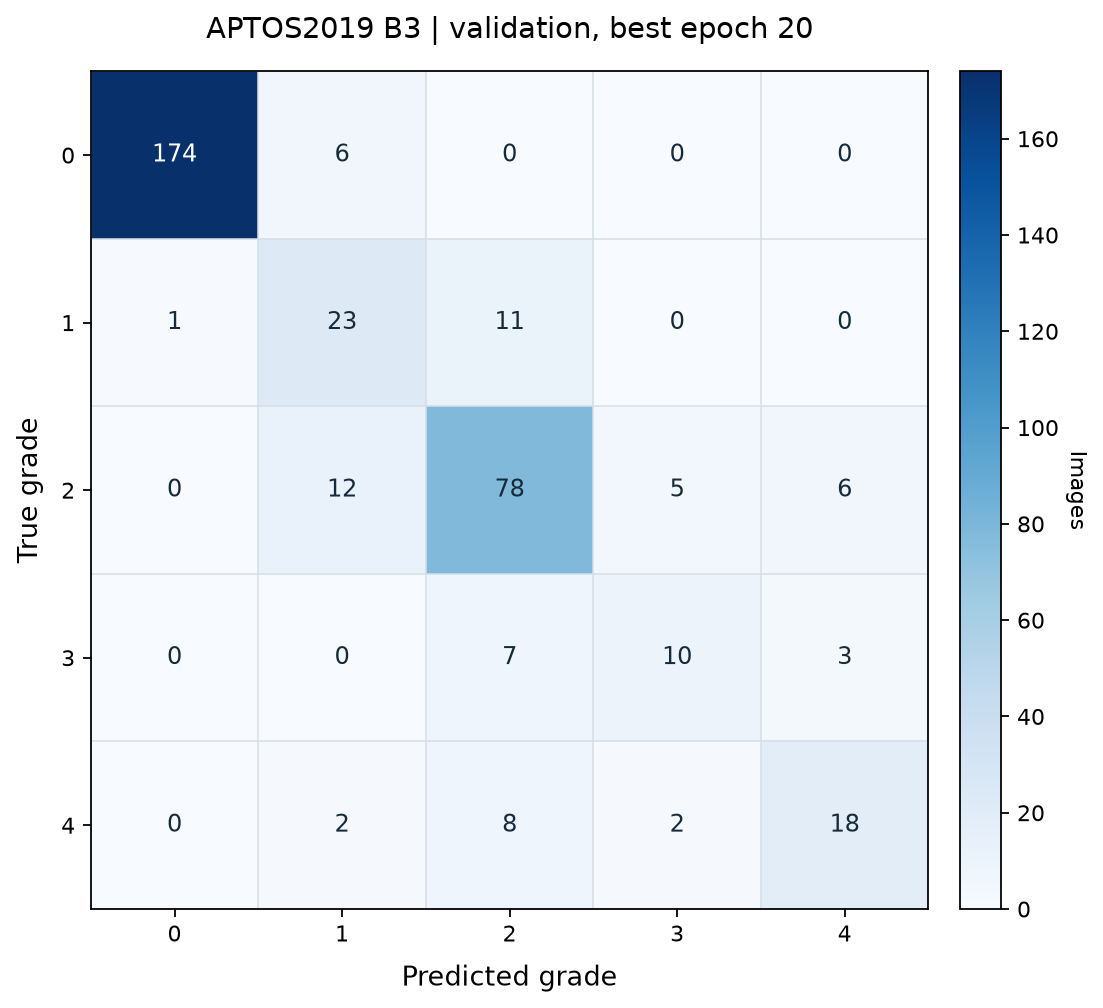

In [ ]:
from IPython.display import Image
display(Image(filename=str(ROOT / 'novelty/convnext_b0_b4/APTOS2019_B3_confusion_matrix.png')))

The next output displays the original train and validation learning curves. Metric coverage follows the corresponding recorded history.

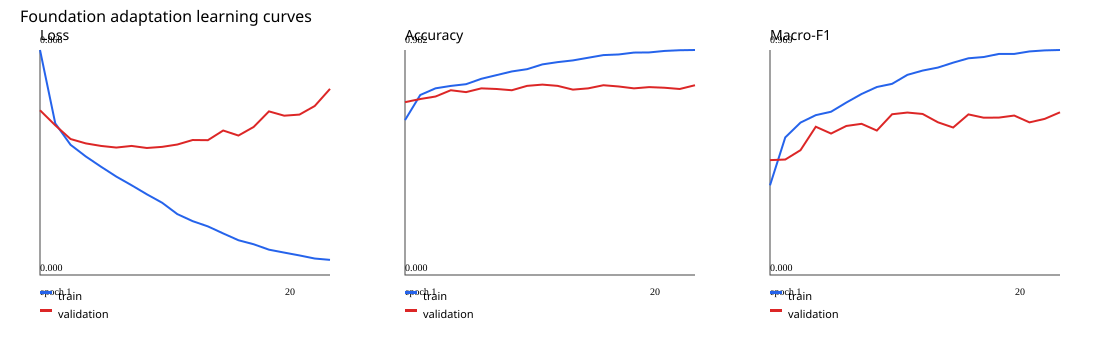

In [ ]:
from IPython.display import SVG
display(SVG(filename=str(ROOT / 'novelty/convnext_b0_b4/APTOS2019_B3_learning_curves.svg')))

## Interpretation and limits

Compared with B1 on this validation split, macro-F1 changed by -0.000500, grade 1 recall by -0.0571, and grade 3 recall by +0.0500.

Screening comparisons share validation data and need independent confirmation. A selected checkpoint is not a final-test result. See the [baseline rationale and audit](../../docs/NOTEBOOK_EXPERIMENT_AUDIT.md#b0b4-mapping).

## Execution availability

The original external orchestration and input selection are prerequisites for a historical rerun. The signed-off reporting path reads aggregate evidence only. There is no substitute training cell for these arms.